# Baseline v1

Спектральные признаки Уэлча и амплитудные статистики из `cache/features_v1`.
Модель читается из `models/baseline_v1.joblib`. Ноутбук не обучает модель и не читает test.
Метрика val — macro-F1 по классам `[0, 1, 2, 3, 4]`, `zero_division=0`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay


def project_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "configs" / "config.yaml").is_file():
            return candidate
    raise FileNotFoundError("configs/config.yaml not found")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import file_sha256, load_config, read_labels
from src.features import align_labels, load_cached_split
from src.train import load_baseline, score_predictions, subject_macro_f1

config = load_config(ROOT / "configs" / "config.yaml")
model_path = config.models_dir / "baseline_v1.joblib"
bundle = load_baseline(model_path)
val = load_cached_split(config.cache_dir, "val")
if tuple(bundle["feature_names"]) != val.feature_names:
    raise RuntimeError("feature names in the model and the cache differ")

labels = read_labels(config.tables_dir / "labels.csv")
y_val, subjects = align_labels(val.ids, labels, "val")
predicted = np.asarray(bundle["model"].predict(val.features), dtype=np.int64)
scores = score_predictions(y_val, predicted)
always = score_predictions(y_val, np.zeros_like(y_val))
by_subject = subject_macro_f1(y_val, predicted, subjects)
classes = list(bundle["classes"])

rows = []
for name, item in (("baseline_v1", scores), ("always_W", always)):
    per_class = item["per_class_f1"]
    rows.append(
        {
            "model": name,
            "macro-F1": item["macro_f1"],
            **{classes[index]: float(per_class[index]) for index in range(len(classes))},
            "accuracy": item["accuracy"],
        }
    )
metrics = pd.DataFrame(rows)
print(
    f"loaded model, train_rows={bundle['train_rows']}, "
    f"val_rows={bundle['val_rows']}, seed={bundle['seed']}"
)
print(f"sha256 {file_sha256(model_path)}")
metrics

loaded model, train_rows=302653, val_rows=43206, seed=42
sha256 dde06e8a59ac81ad8669937f86c592756efde9c0526ac52a67ab4efa4e1f2685


model,macro-F1,W,N1,N2,N3,REM,accuracy
baseline_v1,0.712991,0.955761,0.364876,0.791401,0.760597,0.692319,0.860274
always_W,0.159863,0.799316,0.000000,0.000000,0.000000,0.000000,0.665718


Macro-F1 по каждому субъекту val. В среднем всегда пять классов: отсутствующий класс даёт F1 = 0.

In [2]:
subject_table = pd.DataFrame(
    by_subject,
    columns=["subject_id", "epochs", "classes_present", "macro-F1"],
)
subject_table

subject_id,epochs,classes_present,macro-F1
SC404,5357,"0,1,2,3,4",0.783043
SC407,5580,"0,1,2,3,4",0.843717
SC417,5461,"0,1,2,3,4",0.631371
SC424,5410,"0,1,2,3,4",0.751428
SC426,5520,"0,1,2,3,4",0.735326
SC427,5310,"0,1,2,3,4",0.719491
SC457,5709,"0,1,2,3,4",0.519277
SC459,4859,"0,1,2,3,4",0.531596


Матрица ошибок на val: строки — истинный класс, столбцы — предсказание.

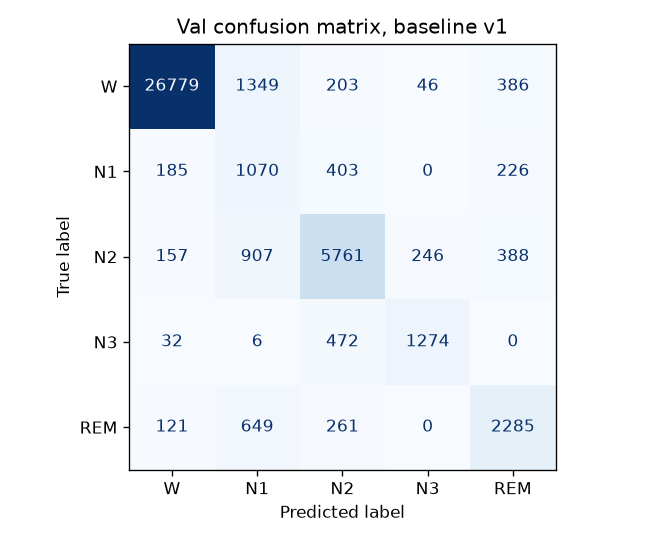

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    scores["confusion_matrix"],
    display_labels=classes,
).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Val confusion matrix, baseline v1")
fig.tight_layout()
plt.show()